In [2]:
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from mhkit.wave.io.ndbc import read_file
from os.path import join as pjoin
import numpy as np
import pandas as pd
import datetime
from tabulate import tabulate

import warnings
np.warnings = warnings 

In [3]:
raw_data_dir = '.'

In [4]:
ndbc_months = ["04", "05"]

ndbc_data_frames = []
ndbc_data_resampled = []
for m in ndbc_months:
    ndbc_data_raw, ndbc_metadata = read_file(pjoin(raw_data_dir, "ndbc", "ndbc_44014_stdmet_2024-"+m+".txt"))
    ndbc_data_frames.append(ndbc_data_raw)

ndbc_data = pd.concat(ndbc_data_frames).to_xarray().rename({"index":"time"})

for q,u in ndbc_metadata.items():
    ndbc_data[q].attrs = {'units': u}



c:\Users\jtgrasb\Anaconda3\lib\site-packages\mhkit\wave\io\ndbc.py:99: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv(
c:\Users\jtgrasb\Anaconda3\lib\site-packages\mhkit\wave\io\ndbc.py:99: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv(


In [7]:
snipRawTimes = [3.921503010698000e+09, 3.922025011357000e+09, 3.921834210532000e+09, 3.921899010806000e+09]
obsNumber = [101, 246, 193, 211]

pioneer_data_JL = xr.load_dataset(pjoin(raw_data_dir,  "ooiSpectra-mab", "WSS_MARK.nc"),decode_times=False)
#print(pioneer_data_JL.sel(obs=0).time.values)

pioneer_data_JL = xr.load_dataset(pjoin(raw_data_dir,  "ooiSpectra-mab", "WSS_MARK.nc"))
pnr_times = pioneer_data_JL.time
print(pnr_times[0])
print(pnr_times[-1])

pioneer_data = xr.load_dataset(pjoin(raw_data_dir,  "ooiSpectra-mab", "deployment0001_CP10CNSM-SBD12-05-WAVSSA000-telemetered-wavss_a_dcl_statistics_20240403T142323.911000-20240606T162324.628000.nc"),decode_times=False)
#print(pioneer_data)

print('Snip times and observation number selected:')
print(snipRawTimes)
print(obsNumber)

print('Nearest snip times and observation number:')
for ind, obsNum in enumerate(obsNumber):
    time = (np.abs(pioneer_data.time - snipRawTimes[ind])).min()
    indTime = (np.abs(pioneer_data.time - snipRawTimes[ind])).argmin()
    print(pioneer_data.sel(obs=indTime).time.values)
    print(indTime.values)



<xarray.DataArray 'time' ()>
array('2024-04-05T00:23:22.899000320', dtype='datetime64[ns]')
Coordinates:
    obs      int32 0
Attributes:
    long_name:      time
    standard_name:  time
    axis:           T
<xarray.DataArray 'time' ()>
array('2024-04-15T23:23:23.019999744', dtype='datetime64[ns]')
Coordinates:
    obs      int32 263
Attributes:
    long_name:      time
    standard_name:  time
    axis:           T
Snip times and observation number selected:
[3921503010.698, 3922025011.357, 3921834210.532, 3921899010.806]
[101, 246, 193, 211]
Nearest snip times and observation number:
3921503003.1359997
100
3922025003.573
245
3921834202.988
192
3921899003.5
210


In [9]:
pioneer_data = xr.load_dataset(pjoin(raw_data_dir,  "ooiSpectra-mab", "deployment0001_CP10CNSM-SBD12-05-WAVSSA000-telemetered-wavss_a_dcl_statistics_20240403T142323.911000-20240606T162324.628000.nc"))
#print(pioneer_data.sel(obs=0).data_vars)
pioneer_data = pioneer_data.set_coords({"time": pioneer_data.port_timestamp})

pioneer_data = pioneer_data.where(pioneer_data.time < np.datetime64('2024-06-01T00:00:00'))

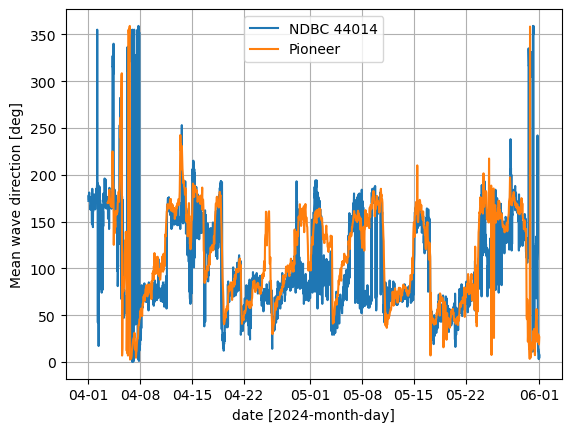

In [10]:
dir = ndbc_data.MWD[np.flatnonzero(np.isfinite(ndbc_data.MWD.values))]

fig, ax = plt.subplots()
ax.plot(dir.time.values, dir.values)
ax.plot(pioneer_data.port_timestamp.values, pioneer_data.mean_direction.values)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
plt.xlabel('date [2024-month-day]')
plt.ylabel('Mean wave direction [deg]')
plt.legend(['NDBC 44014', 'Pioneer'])
plt.grid()

In [11]:
print(pioneer_data.time)

<xarray.DataArray 'time' (obs: 1539)>
array(['2024-04-03T14:23:23.911000064', '2024-04-03T15:23:22.941000192',
       '2024-04-03T16:23:23.966000128', ...,
       '2024-06-06T14:23:22.593999872', '2024-06-06T15:23:22.607000576',
       '2024-06-06T16:23:24.628000256'], dtype='datetime64[ns]')
Coordinates:
  * obs      (obs) int32 0 1 2 3 4 5 6 7 ... 1532 1533 1534 1535 1536 1537 1538
    time     (obs) datetime64[ns] 2024-04-03T14:23:23.911000064 ... 2024-06-0...
Attributes:
    long_name:      time
    standard_name:  time
    axis:           T


+--------+---------------------+-------+-------------------------------+-------------------------------+------------+---------------+--------------+---------------+
|   Snip | Time                |   Obs | NDBC Time                     | Pioneer Time                  |   NDBC Dir |   Pioneer Dir |   Pioneer Tp |   Pioneer Hm0 |
+========+=====================+=======+===============================+===============================+============+===============+==============+===============+
|    202 | 2024-04-07 18:00:00 |   101 | 2024-04-07T18:25:00.000000000 | 2024-04-07T17:23:24.102999552 |      359   |          29.1 |          4.7 |          1.23 |
+--------+---------------------+-------+-------------------------------+-------------------------------+------------+---------------+--------------+---------------+
|    419 | 2024-04-13 19:00:00 |   246 | 2024-04-13T19:25:00.000000000 | 2024-04-13T18:23:23.550000128 |      158.5 |         201.6 |          6.1 |          1.31 |
+--------+

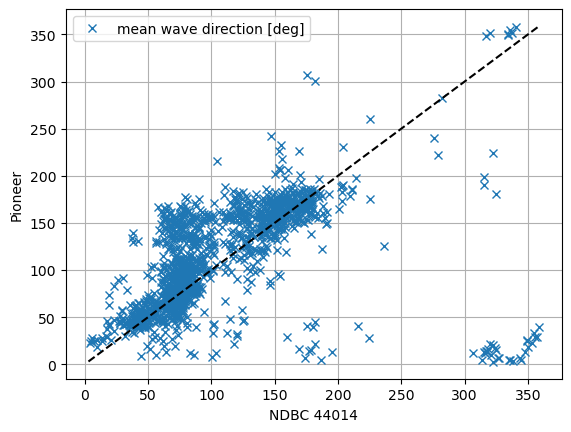

In [12]:
pioneer_start = pioneer_data.time.values[0]

# Take NDBC data from 10minute to hourly to match pioneer
ndbc_hourly = ndbc_data.coarsen(time=6, boundary="trim").mean()
ndbc_hourly_dir = ndbc_hourly.MWD.where(ndbc_hourly.time > pioneer_start).dropna("time")

# Convert time to seconds to allow interpolation.
pioneer_time_int = pioneer_data.time.values.astype("datetime64[s]").astype("int")
ndbc_time_int = ndbc_hourly_dir.time.values.astype("datetime64[s]").astype("int")

# Interpolate the pioneer data to match ndbc timestamps
pioneer_dir_interp = np.interp(ndbc_time_int, pioneer_time_int, pioneer_data.mean_direction.values)

fig, ax = plt.subplots()
ax.plot(ndbc_hourly_dir.values, pioneer_dir_interp, 'x')
ax.plot(np.linspace(3, np.max(ndbc_hourly_dir.values)), np.linspace(3, np.max(ndbc_hourly_dir.values)), 'k--')
plt.xlabel('NDBC 44014')
plt.ylabel('Pioneer')
plt.legend(['mean wave direction [deg]'])
plt.grid()

# extract data for snips
snip202Time = datetime.datetime(2024,4,7,18,10)

snips = [202, 419, 313, 349]
snipTimes = [datetime.datetime(2024,4,7,18), datetime.datetime(2024,4,13,19), datetime.datetime(2024,4,11,14), datetime.datetime(2024,4,12,8)]
snipRawTimes = [3.921503010698000e+09, 3.922025011357000e+09, 3.921834210532000e+09, 3.921899010806000e+09]
obsNumber = [101, 246, 193, 211]

dataHeaders = ["Snip","Time","Obs","NDBC Time","Pioneer Time","NDBC Dir","Pioneer Dir","Pioneer Tp","Pioneer Hm0"]
dataTable = []

nearestPioneer = pioneer_data.sel(obs=obsNumber[0]-1,method='nearest')
#print(nearestPioneer)

for snip, snipTime, obsNum in zip(snips,snipTimes,obsNumber):
    nearestNDBC = ndbc_hourly.sel(time=snipTime,method='nearest')
    nearestPioneer = pioneer_data.sel(obs=obsNum-1,method='nearest')
    dataTable.append([snip,snipTime,obsNum,str(nearestNDBC.time.values),str(nearestPioneer.time.values),nearestNDBC.MWD.values,nearestPioneer.mean_direction.values,nearestPioneer.significant_period,nearestPioneer.significant_wave_height.values])

# display table
print(tabulate(dataTable, headers=dataHeaders, tablefmt="grid"))

nearestNDBC = ndbc_hourly.sel(time=snipTimes[3],method='nearest')
#print(nearestNDBC.data_vars)
nearestPioneer = pioneer_data.sel(obs=obsNumber[3],method='nearest')
#print(nearestPioneer.data_vars)


In [13]:
# import module
from tabulate import tabulate
 
# assign data
mydata = [
    [2, "Delhi"], 
    [4, "Kanpur"], 
    [4, "Ahmedabad"], 
      [5, "Bangalore"]
]

print(mydata[0][1])
# create header
head = ["Name", "City"]
 
# display table
print(tabulate(mydata, headers=head, tablefmt="grid"))

Delhi
+--------+-----------+
|   Name | City      |
+========+===========+
|      2 | Delhi     |
+--------+-----------+
|      4 | Kanpur    |
+--------+-----------+
|      4 | Ahmedabad |
+--------+-----------+
|      5 | Bangalore |
+--------+-----------+


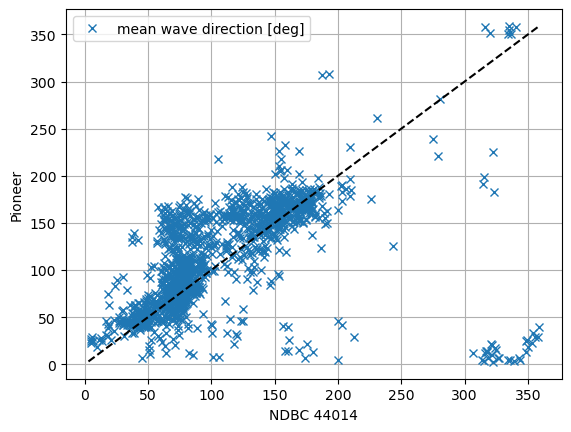

In [14]:
# Performing the interpolation the other way around
ndbc_dir = ndbc_data.MWD.dropna("time")

ndbc_time_int_2 = ndbc_dir.time.values.astype("datetime64[s]").astype("int")
ndbc_dir_interp = np.interp(pioneer_time_int, ndbc_time_int_2, ndbc_dir.values)

fig, ax = plt.subplots()
ax.plot(ndbc_dir_interp, pioneer_data.mean_direction.values, 'x')
ax.plot(np.linspace(3, np.max(ndbc_dir_interp)), np.linspace(3, np.max(ndbc_dir_interp)), 'k--')
plt.xlabel('NDBC 44014')
plt.ylabel('Pioneer')
plt.legend(['mean wave direction [deg]'])
plt.grid()
